# 03 · Price Forecast — Can we plan with prices we don't know yet?

**Project:** Industrial Load Shifting  **Week:** 3  **Author:** Swaroop Jadhav

### Why this notebook exists
The Week 2 upper bound assumed we know every price in advance. A production planner does not:
the exchange publishes **tomorrow's** prices around noon each day. A plan made on day **D** therefore
knows prices up to **D+1** and needs a **forecast for D+2 … D+7** (horizon 2–7 days).

| Day | D (planning day) | D+1 | D+2 … D+7 |
|---|---|---|---|
| Prices | known | known (auction at noon on D) | **must be forecast** |

**Golden rule:** every input must be known on the planning day. Using anything from later
("data leakage") makes a model look great in testing and fail in reality.

### Business questions
1. How accurately can prices be forecast 2–7 days ahead from price history and the calendar?
2. Does machine learning (LightGBM) beat simple rules?
3. **Does a better forecast actually save more money?** (accuracy ≠ business value)

**Prerequisites:** `pip install -r requirements.txt` (adds LightGBM and holidays), Week 1 & 2 data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))
import config
import cost
import forecast as fc

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODEL_COLORS = dict(zip(fc.MODELS, COLORS))          # fixed colour per model in every chart

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

---
## Part A · The forecasting dataset

One row = one quarter-hour of one target day, for one horizon (2–7 days ahead). The inputs come in two groups:

| Group | Features | Known on planning day? |
|---|---|---|
| **Calendar** of the target day | quarter-hour, hour, weekday, month, season (sin/cos), public holiday (Baden-Württemberg) | ✅ always |
| **Recent prices** | same quarter on the last known day, its daily shape, min/max/mean of that day, same weekday last week, 7-day averages | ✅ only up to D+1 |

⚠️ **Not included: weather** (wind and solar forecasts), which drive the price level. See assumption A7.

In [2]:
prices = pd.read_csv(config.PRICES_RAW_FILE, parse_dates=["timestamp_utc"])
data = fc.build_dataset(prices)
print(f"{len(data):,} rows = {data['target_date'].nunique()} target days x 6 horizons x 96 quarter-hours")
print(f"Target days: {data['target_date'].min():%d %b %Y} to {data['target_date'].max():%d %b %Y} "
      "(the first week is needed to build the 7-day features)")
data.head(3).T

204,768 rows = 358 target days x 6 horizons x 96 quarter-hours
Target days: 08 Oct 2025 to 30 Sep 2026 (the first week is needed to build the 7-day features)


,0,1,2
target_date,2025-10-08 00:00:00,2025-10-08 00:00:00,2025-10-08 00:00:00
horizon,2,2,2
quarter,0,1,2
hour,0,0,0
weekday,2,2,2
month,10,10,10
doy_sin,-0.992629,-0.992629,-0.992629
doy_cos,0.121193,0.121193,0.121193
is_holiday,0,0,0
last_known_is_holiday,0,0,0


---
## Part B · Honest testing: rolling-origin backtest

We pretend to use the model in real life, month by month (decision D12):
for each test month (**Mar – Sep 2026**) the model is trained **only on days before that month** (with a
7-day safety gap), then forecasts the month. Then the next month gets one more month of training data.

Three simple rules are the **baselines** every model must beat:
- **Last known day:** "the target day looks like tomorrow"
- **Same day last week:** "next Tuesday looks like last Tuesday"
- **7-day average:** average of each quarter-hour over the last 7 known days

In [3]:
test_months = [f"2026-{m:02d}" for m in range(3, 10)]
results, last_model = fc.rolling_backtest(data, test_months)
overall = fc.accuracy_table(results).set_index("model").sort_values("MAE")
overall.round(3)

  2026-03: trained on 137 days, tested on 31 days


  2026-04: trained on 168 days, tested on 30 days


  2026-05: trained on 198 days, tested on 31 days


  2026-06: trained on 229 days, tested on 30 days


  2026-07: trained on 259 days, tested on 31 days


  2026-08: trained on 290 days, tested on 31 days


  2026-09: trained on 321 days, tested on 30 days


,MAE,RMSE,rank_corr
model,,,
Naive: 7-day average,37.883,55.592,0.898
LightGBM,38.804,54.981,0.861
Naive: same day last week,42.596,65.683,0.869
Naive: last known day,43.842,66.913,0.843


**How to read it:**
- **MAE** = average absolute error in €/MWh (lower is better). **RMSE** punishes big misses more (spikes).
- **rank_corr** = how well the forecast puts the quarter-hours *within each day* in the right order
  (1 = perfect order). For load shifting this matters more than the exact level.

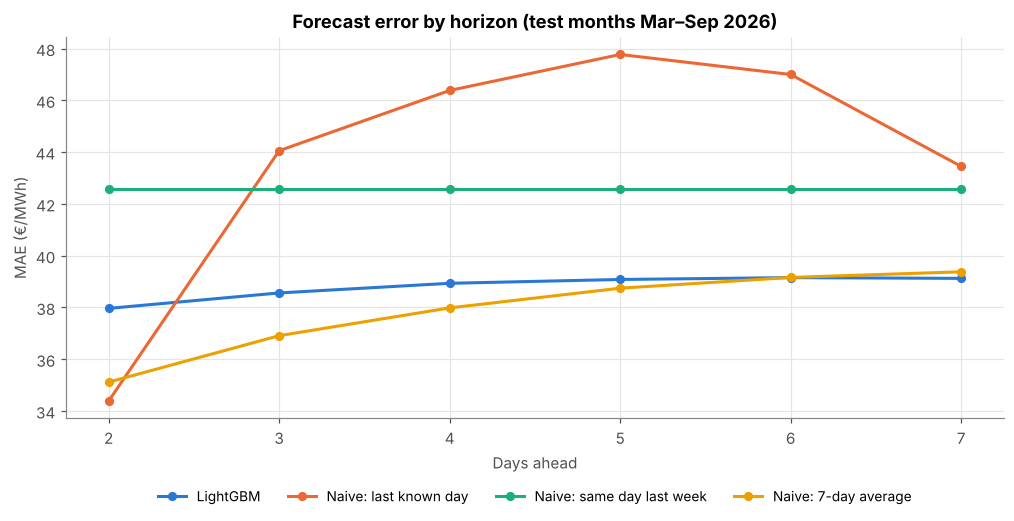

model,LightGBM,Naive: 7-day average,Naive: last known day,Naive: same day last week
horizon,,,,
2,38.0,35.1,34.4,42.6
3,38.6,36.9,44.1,42.6
4,38.9,38.0,46.4,42.6
5,39.1,38.7,47.8,42.6
6,39.2,39.2,47.0,42.6
7,39.1,39.4,43.5,42.6


In [4]:
by_h = fc.accuracy_table(results, by="horizon").pivot(index="horizon", columns="model", values="MAE")
fig, ax = plt.subplots()
for m in fc.MODELS:
    ax.plot(by_h.index, by_h[m], color=MODEL_COLORS[m], marker="o", markersize=5, label=m)
ax.set(title="Forecast error by horizon (test months Mar–Sep 2026)", xlabel="Days ahead",
       ylabel="MAE (€/MWh)", xticks=list(by_h.index))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=4, fontsize=9)
save(fig, "W3_B_error_by_horizon")
plt.show()
by_h.round(1)

**✍️ Your interpretation:** *Which method is the most accurate? Does LightGBM beat the simple rules? How fast does the error grow with the horizon, and why is 'same day last week' a flat line?*

> The most accurate method overall is actually the simplest one: the 7-day average, with an average error (MAE) of 37.9 €/MWh. LightGBM comes second with 38.8 €/MWh, so it does not beat the simple rule. It only has a slightly lower RMSE (55.0 vs 55.6), which means it makes a few less extreme mistakes. I also tried letting LightGBM predict only the deviation from the 7-day average, but that did not help either.
>
> Looking at the horizons, the "last known day" rule is the best for 2 days ahead (34.4 €/MWh), because then the last known day is just the day before the target. But after that its error jumps to 44 to 48 €/MWh. The 7-day average gets slowly worse from 35.1 to 39.4 €/MWh, and LightGBM stays almost flat around 38 to 39 €/MWh, so at 6 to 7 days ahead it is about as good as the 7-day average. The "same day last week" line is flat because it always uses the price from exactly 7 days before the target day, no matter when the plan is made.

---
## Part C · What the forecasts look like

One test week (Mon 4 – Sun 10 May 2026), forecast **2 days ahead**.

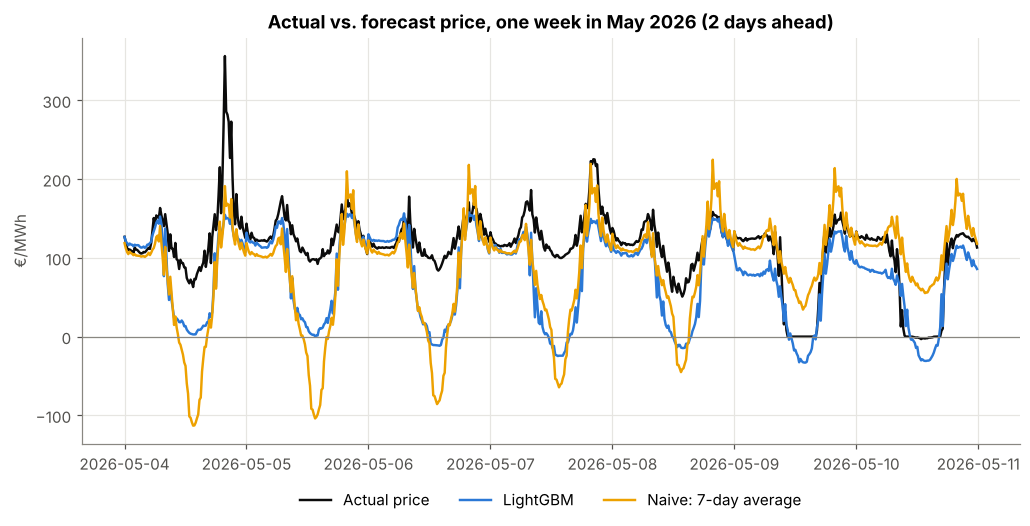

In [5]:
week = results[(results["horizon"] == 2) &
               (results["target_date"] >= "2026-05-04") & (results["target_date"] <= "2026-05-10")]
week = week.sort_values(["target_date", "quarter"])
x = week["target_date"] + pd.to_timedelta(week["quarter"] * 15, unit="min")

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(x, week["actual"], color="#0b0b0b", linewidth=1.6, label="Actual price")
for m in ["LightGBM", "Naive: 7-day average"]:
    ax.plot(x, week[m], color=MODEL_COLORS[m], linewidth=1.6, label=m)
ax.axhline(0, color="#898781", linewidth=0.8)
ax.set(title="Actual vs. forecast price, one week in May 2026 (2 days ahead)", ylabel="€/MWh")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncols=3)
save(fig, "W3_C_example_week")
plt.show()

**✍️ Your interpretation:** *Where are the forecasts good and where do they fail? Look at the daily shape (midday dip, evening peak) vs. the extreme values (negative prices, spikes).*

> The forecasts get the daily shape right: they know that the price drops around midday and goes up in the morning and in the evening, and the timing of these peaks and dips is quite accurate. What they get wrong is the level. From Monday 4 to Friday 8 May both forecasts expected a deep midday dip, but the actual price stayed at around 70 to 100 €/MWh, probably because it was a cloudy week with less solar. Only on the weekend (9 and 10 May) did the price really drop to around 0, and there the forecasts were close.
>
> The 7-day average was especially wrong at the start of the week, with forecasts down to −100 €/MWh. I think this is because its last 7 days included the 1 May holiday with prices at −500 €/MWh, which pulled the average down. LightGBM was less extreme here. None of the methods saw the price spike to about 350 €/MWh on the evening of 4 May. So the forecasts are good at the regular pattern but cannot predict weather-driven days or spikes.

### C2. What does LightGBM rely on?
Feature importance (total gain) of the model trained for the last test month.

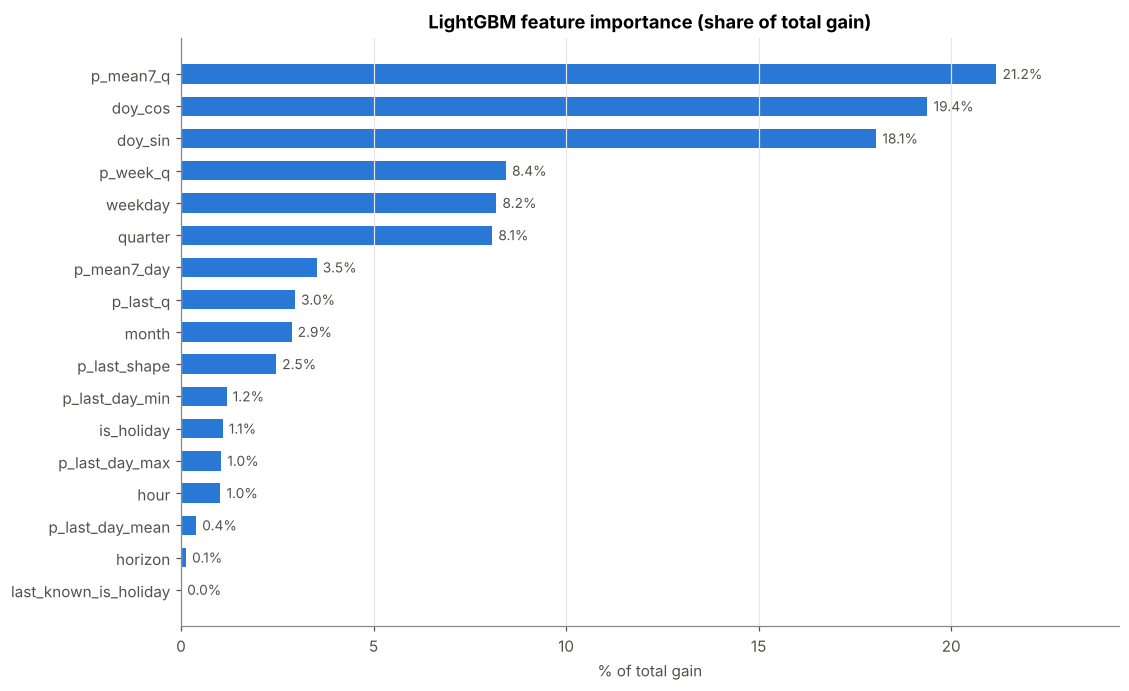

In [6]:
imp = pd.Series(last_model.booster_.feature_importance("gain"), index=fc.FEATURES)
imp = (100 * imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(11, 0.35 * len(imp) + 1))
ax.barh(imp.index, imp.values, color=COLORS[0], height=0.6)
for y, v in enumerate(imp.values):
    ax.annotate(f"{v:.1f}%", xy=(v, y), xytext=(4, 0), textcoords="offset points", va="center",
                color="#52514e", fontsize=9)
ax.set(title="LightGBM feature importance (share of total gain)", xlabel="% of total gain",
       xlim=(0, imp.max() * 1.15))
ax.grid(axis="y", visible=False)
save(fig, "W3_C2_feature_importance")
plt.show()

**✍️ Your interpretation:** *Which inputs matter most? What does that tell you about what drives prices 2–7 days ahead, and what information is the model missing?*

> The model relies mostly on three things: the recent 7-day average of the same quarter-hour (21%), the season (day of year, together about 37%), and the weekly and daily rhythm (same day last week, weekday and quarter-hour, about 8% each). Holidays play almost no role (1%), and the horizon is almost unused (0.1%), which fits the flat error curve.
>
> So the model mainly learns regular patterns: what time of day, which weekday and which season it is, and what prices were recently. Nothing in the data tells it whether it will be sunny or windy, and that is what really moves the price level days ahead. Another problem is that I only have one year of prices. When the model forecasts June, it has never seen a June before, so the season features are hard to learn properly. Weather forecasts and more years of price history would be the two main improvements.

---
## Part D · Does a better forecast save more money?

This is the question a business cares about. We plan every machine's **production energy** with each
forecast (same-day shifting, as in the Week 2 upper bound), but **pay the actual prices**. Then we compare with:
- **No shifting** — today's schedule
- **Perfect knowledge** — the Week 2 upper bound (knowing all prices in advance)

**captured_%** = how much of the perfect-knowledge saving each forecast achieves in reality.
Test period: Mar – Sep 2026.

In [7]:
loads = pd.read_csv(config.SPARK_LOAD_FILE, parse_dates=["timestamp_utc"])
aligned = cost.align_load_to_prices(loads, prices)

dv = {h: fc.decision_value(results, aligned, horizon=h) for h in (2, 7)}
print(f"Test period: {dv[2].attrs['days']} days")
summary = pd.concat({f"{h} days ahead": d[["saving_eur", "captured_%"]] for h, d in dv.items()}, axis=1)
summary.round(1)

Test period: 214 days


2 days ahead            7 days ahead           
                            saving_eur captured_%   saving_eur captured_%
No shifting                        0.0        0.0          0.0        0.0
Perfect knowledge               1736.2      100.0       1736.2      100.0
LightGBM                        1614.3       93.0       1601.7       92.3
Naive: last known day           1666.1       96.0       1638.7       94.4
Naive: same day last week       1631.5       94.0       1631.5       94.0
Naive: 7-day average            1692.5       97.5       1673.6       96.4

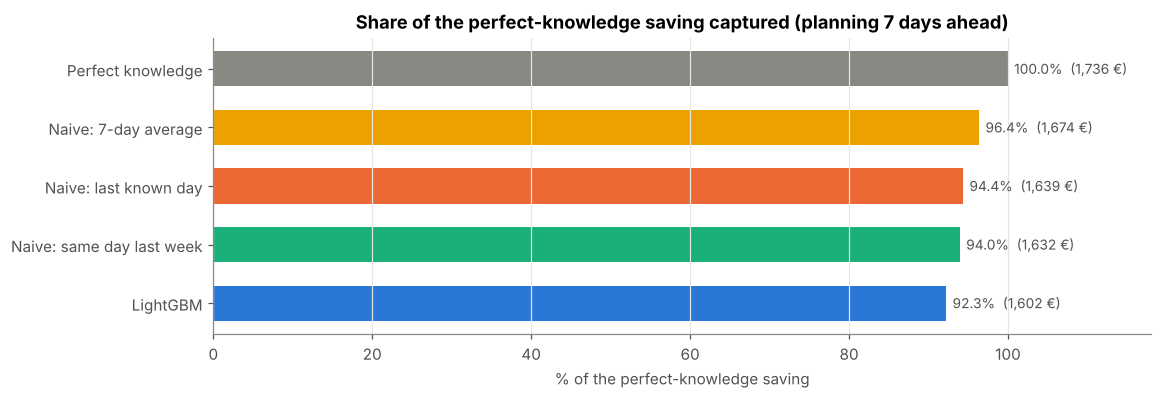

In [8]:
d7 = dv[7].drop(index=["No shifting"])["captured_%"].sort_values()
fig, ax = plt.subplots(figsize=(11, 0.5 * len(d7) + 1))
colors = ["#898781" if m == "Perfect knowledge" else MODEL_COLORS[m] for m in d7.index]
ax.barh(d7.index, d7.values, color=colors, height=0.6)
for y, (m, v) in enumerate(d7.items()):
    ax.annotate(f"{v:.1f}%  ({dv[7].loc[m, 'saving_eur']:,.0f} €)", xy=(v, y), xytext=(4, 0),
                textcoords="offset points", va="center", color="#52514e", fontsize=9)
ax.set(title="Share of the perfect-knowledge saving captured (planning 7 days ahead)",
       xlabel="% of the perfect-knowledge saving", xlim=(0, 118))
ax.grid(axis="y", visible=False)
save(fig, "W3_D_decision_value")
plt.show()

**✍️ Your interpretation:** *How much of the possible saving does each forecast capture? Why is the difference between the methods so small, even though their errors differ? Which forecast would you use in Week 4, and why?*

> With perfect knowledge of all prices, same-day shifting would have saved €1,736 on production energy over the 214 test days (March to September 2026). The 7-day average captures 97.5% of that when planning 2 days ahead and 96.4% when planning 7 days ahead. The other simple rules capture about 94 to 96%, and LightGBM is the lowest with 92 to 93%.
>
> The differences are small because same-day shifting only needs to know the order of the hours within a day, not the exact price. All methods know that midday is usually cheap and the morning and evening are expensive, so they mostly put the energy in the right hours. This also explains why LightGBM is last even though its error is close to the 7-day average: it has the worst within-day ranking (rank correlation 0.86 vs 0.90). For Week 4 I will use the 7-day average. It ranks the hours best, captures the most saving, needs no training and is easy to explain to a plant manager.

---
## Key findings (Week 3)
*3–5 bullets: best method and its error, whether ML helped, decision value, which forecast to use, what would improve it.*

1. With only price history and the calendar, the simple 7-day average is the most accurate forecast (MAE 37.9 €/MWh). LightGBM does not beat it (38.8 €/MWh), even when it only predicts the deviation from the average.
2. The forecasts get the daily shape right (midday dip, morning and evening peaks) but miss the level on weather-driven days and price spikes. Weather data is the most important missing input.
3. For same-day load shifting, forecast accuracy barely matters: even planning 7 days ahead, the 7-day average captures 96% of the saving that perfect knowledge would give (€1,674 of €1,736 over 7 months).
4. Ranking the hours correctly within a day matters more than a low average error. LightGBM has a similar error but the worst ranking, so it captures the least saving (92%).
5. Decision for Week 4: plan with the 7-day average, the simplest method that works. Better forecasts (weather, more years of data) would mainly help if jobs were moved between days, not within a day.

## Next step (Week 4)
Turn the upper bound into a **realistic plan**: optimise when each flexible machine runs, using the chosen
forecast, with production rules (shift times, job lengths, machines that must run together).